Measure the gap between the average head and the head in the wells for different pumping rates and different settings.

In [1]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from tqdm import trange
import copy

import cvxpy as cp
import gurobipy as gp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import SquareCoarseModel, SquareCoarseExtendedModel
from Components.Controllers import LTI_LQRc_RHG, LTI_LQRc_RHG_mixed_state, LQRc_welfare
from Components.Solver import fbrs

In [2]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

In [3]:
parameter_file = "Components/Setup/aquifer_parameters.json"

In [4]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = SquareCoarseExtendedModel(parameter_file, boundary_condition="Constant Head")

In [5]:
# Initialize Controller
controller = LTI_LQRc_RHG_mixed_state(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    [A.toarray() for A in model.A_s_v], [B.toarray() for B in model.B_s_v], [C.toarray() for C in model.C_s_v],
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    None, None,
    Q_v = [G.toarray() for G in model.Gamma_v_tilde], R_v = None, M_v = None, L_v = [Xi for Xi in model.Xi_v],
    solver='fbrs'
)

In [6]:
# Transform into welfare controller
welfare = LQRc_welfare(controller)

In [7]:
# Initialize receding horizon
receding_horizon = RecedingHorizon(system, model, welfare, parameter_file)

Simulation progress: 100%|██████████| 200/200 [01:28<00:00,  2.26it/s]
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:113: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_h.show()
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:114: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_q.show()
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:115: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_p.show()


array([[[9.999566 , 9.999132 , 9.998697 , ..., 9.997731 , 9.998487 , 9.999244 ],
        [9.999132 , 9.998264 , 9.997395 , ..., 9.995462 , 9.996975 , 9.998487 ],
        [9.998699 , 9.997397 , 9.996094 , ..., 9.993193 , 9.995461 , 9.997731 ],
        ...,
        [9.998813 , 9.997624 , 9.996435 , ..., 9.98863  , 9.9924345, 9.996222 ],
        [9.9992075, 9.998416 , 9.9976225, ..., 9.992406 , 9.994947 , 9.997477 ],
        [9.999604 , 9.9992075, 9.998811 , ..., 9.996199 , 9.997471 , 9.998736 ]]], shape=(1, 100, 100), dtype=float32)

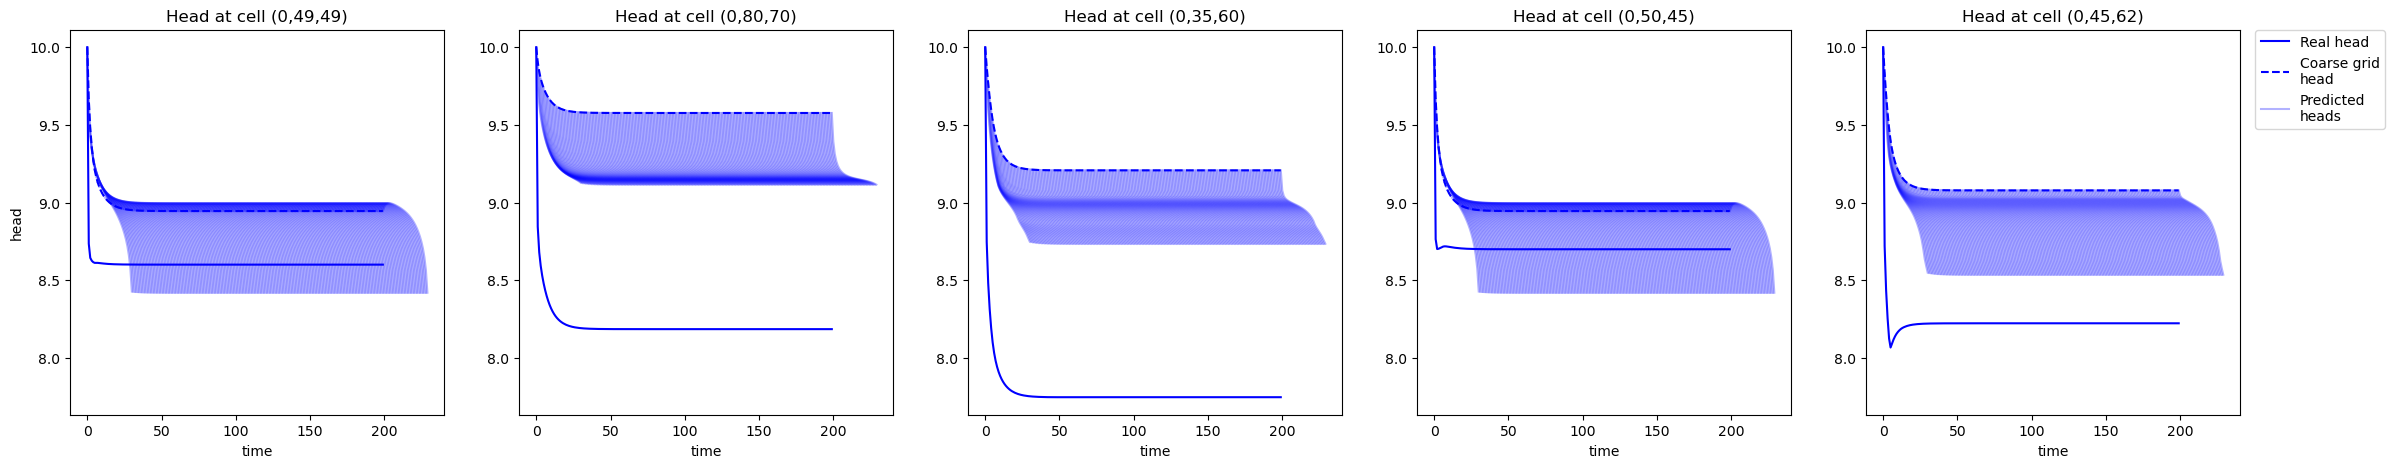

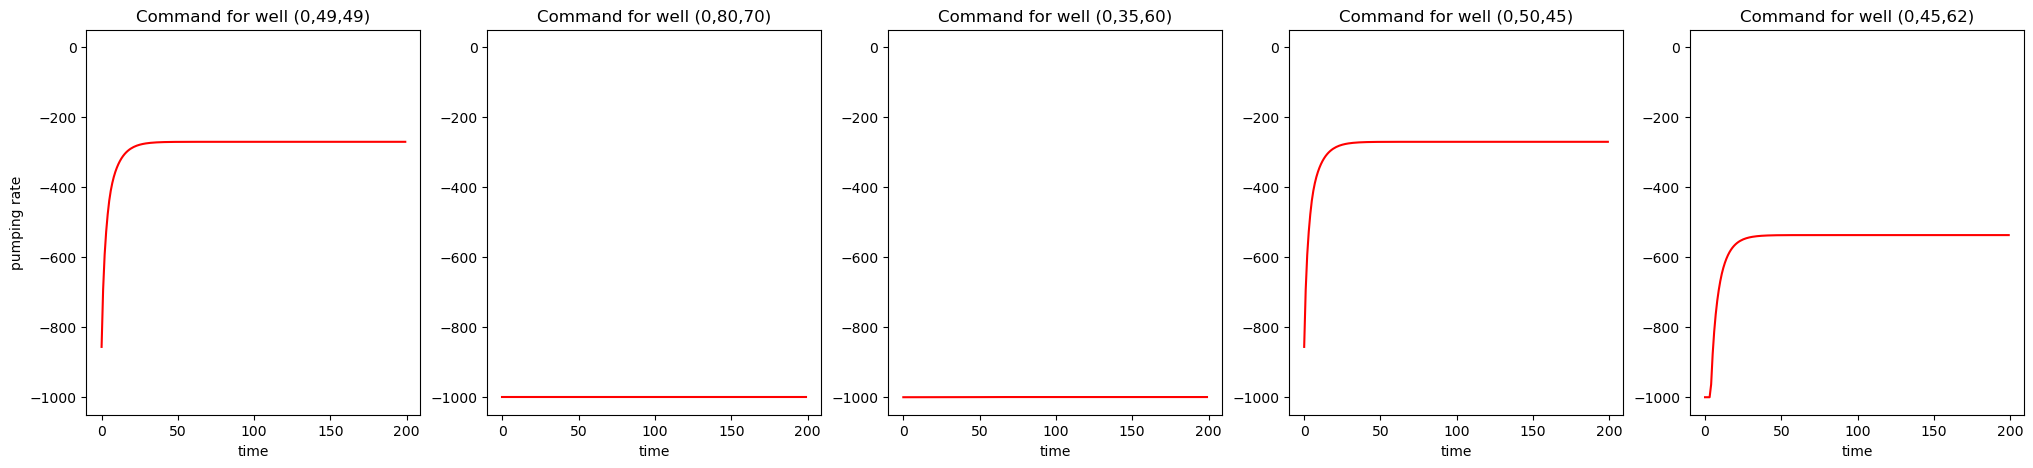

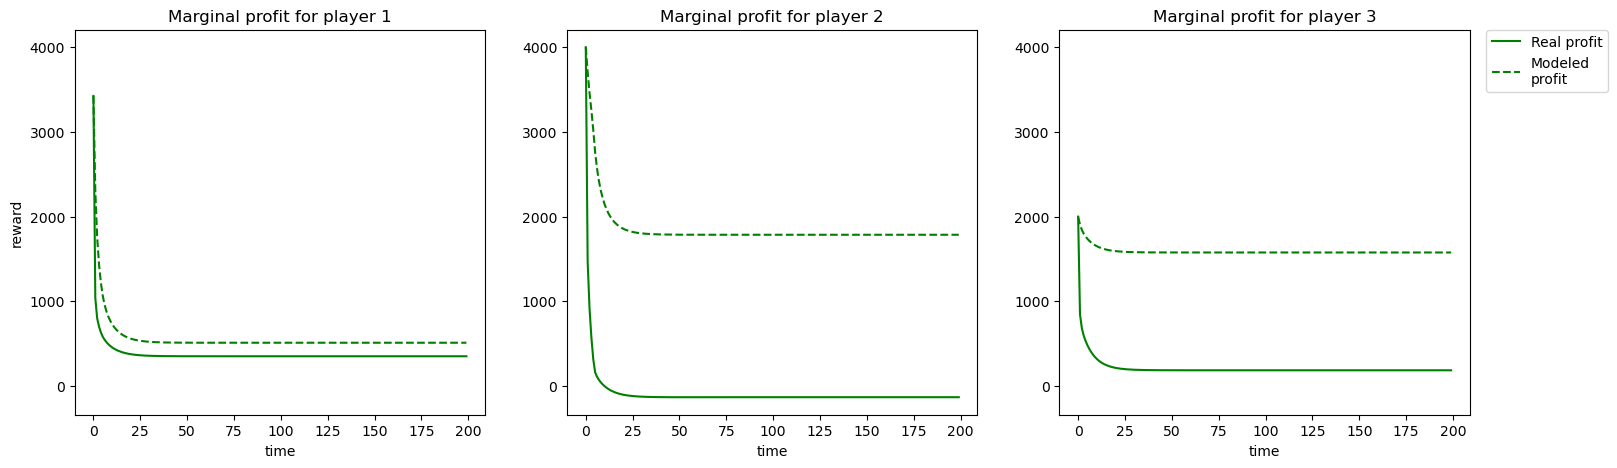

In [8]:
# Run loop
receding_horizon.run(time_period=200, display_results=True)

# Compare Welfare and Self-interested agents

In [9]:
data_si = np.load("run_data/run_20250516-183948/result_data.npz")
data_wf = np.load("run_data/run_20250526-111922/result_data.npz")

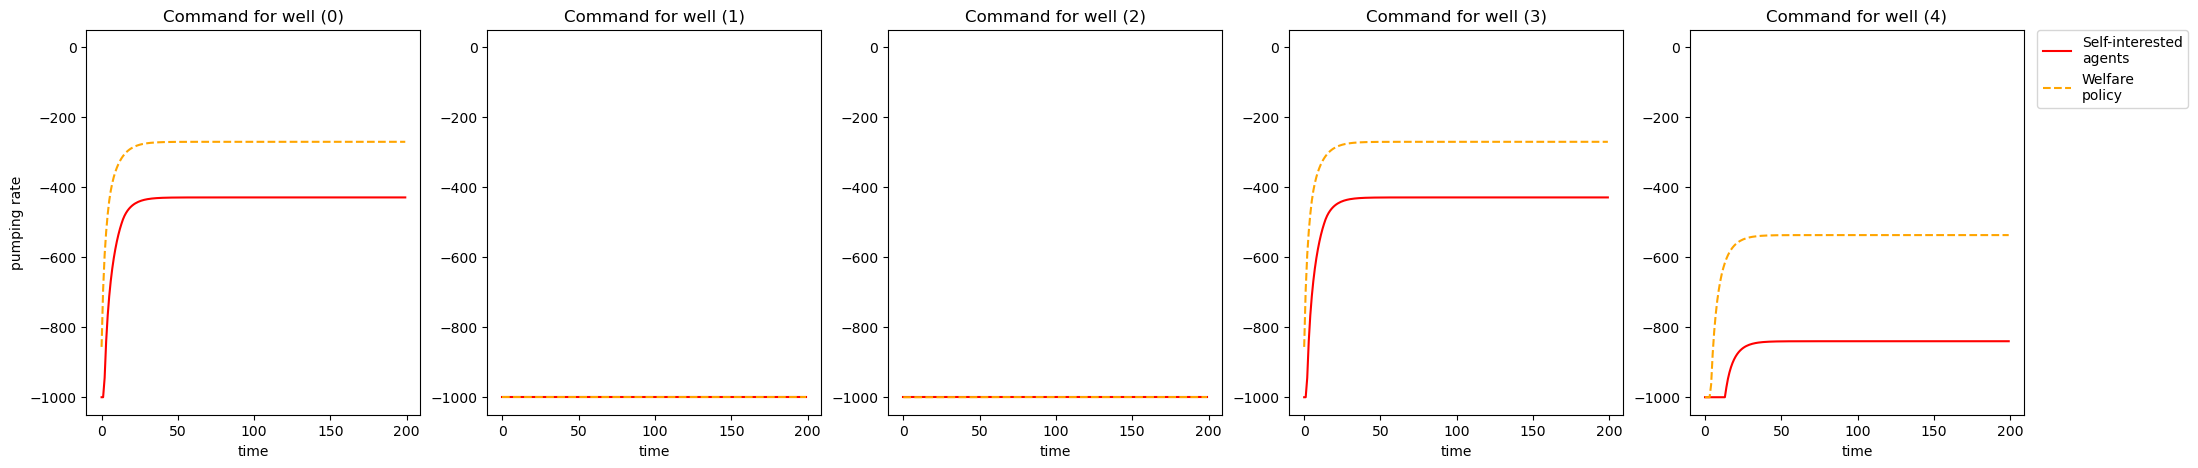

In [13]:
fig_q = plt.figure(figsize=(25,5))
ax_q = None
for ii in range(5):
    ax_q = fig_q.add_subplot(1, 5, ii+1, sharey=ax_q)
    ttl = f"Command for well ({ii})"
    ax_q.set_title(ttl)
    ax_q.set_xlabel("time")
    if ii == 0:
        ax_q.set_ylabel("pumping rate")
    ax_q.plot(data_si['q_rates'][ii, :], "r-", label="Self-interested\nagents")
    ax_q.plot(data_wf['q_rates'][ii, :], color="orange", linestyle="--", label="Welfare\npolicy")
    ax_q.set_ylim([-1050, 50])
ax_q.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

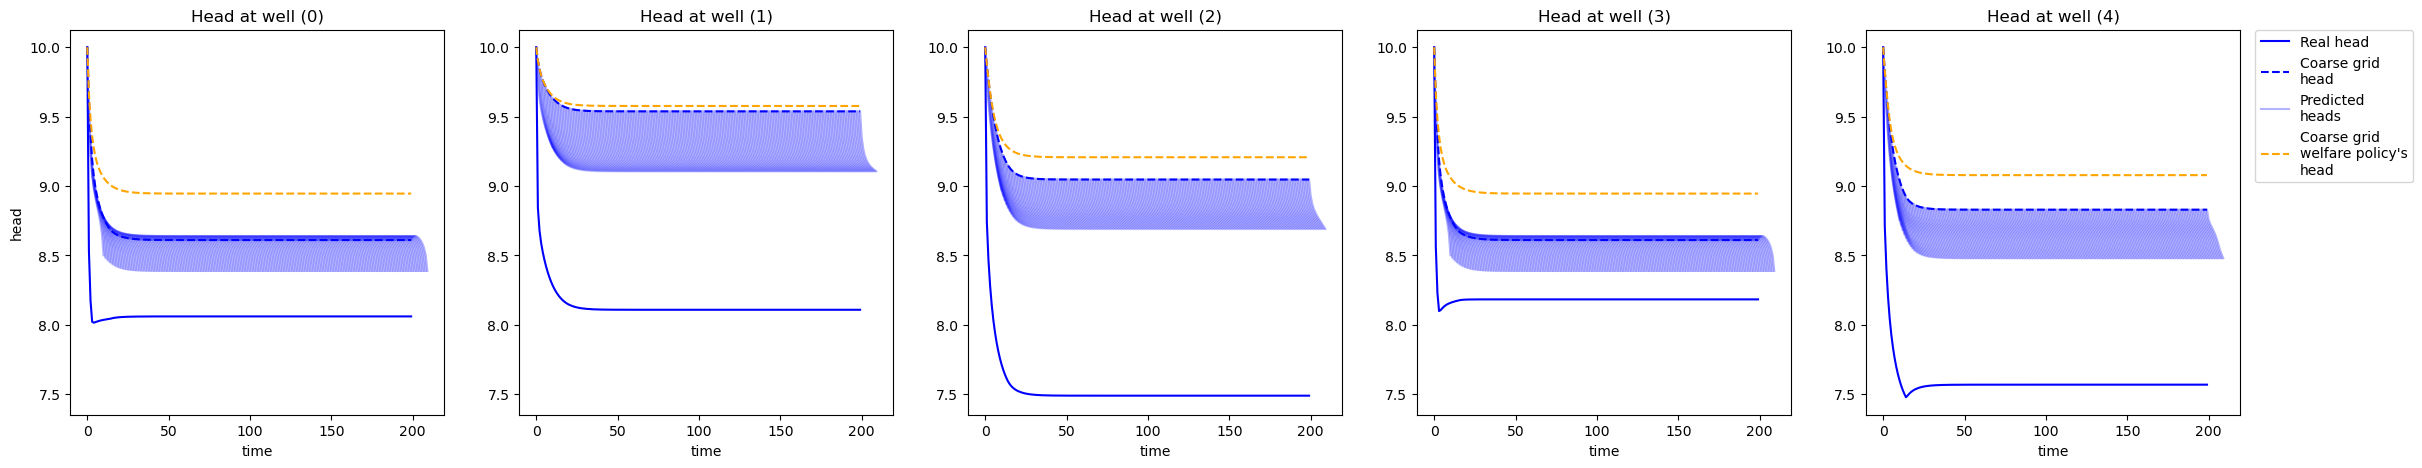

In [ ]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data_si['h_wells'][ii, :], "b-", label="Real head")
    ax_h.plot(data_si['avg_h_wells'][ii, :], "b--", label="Coarse grid\nhead")
    # Display predicted evolution
    dt = np.linspace(0,10, 11)
    for t0, h_pred in enumerate(np.rollaxis(data_si['pred_avg_h_wells'], 2)):
        t = t0 + dt
        ax_h.plot(t, h_pred[ii, :], "b-", alpha=0.3,
                    label="Predicted\nheads" if t0==0 else None)
    ax_h.plot(data_wf['avg_h_wells'][ii, :], color="orange", linestyle="--", label="Coarse grid\nwelfare policy's\nhead")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

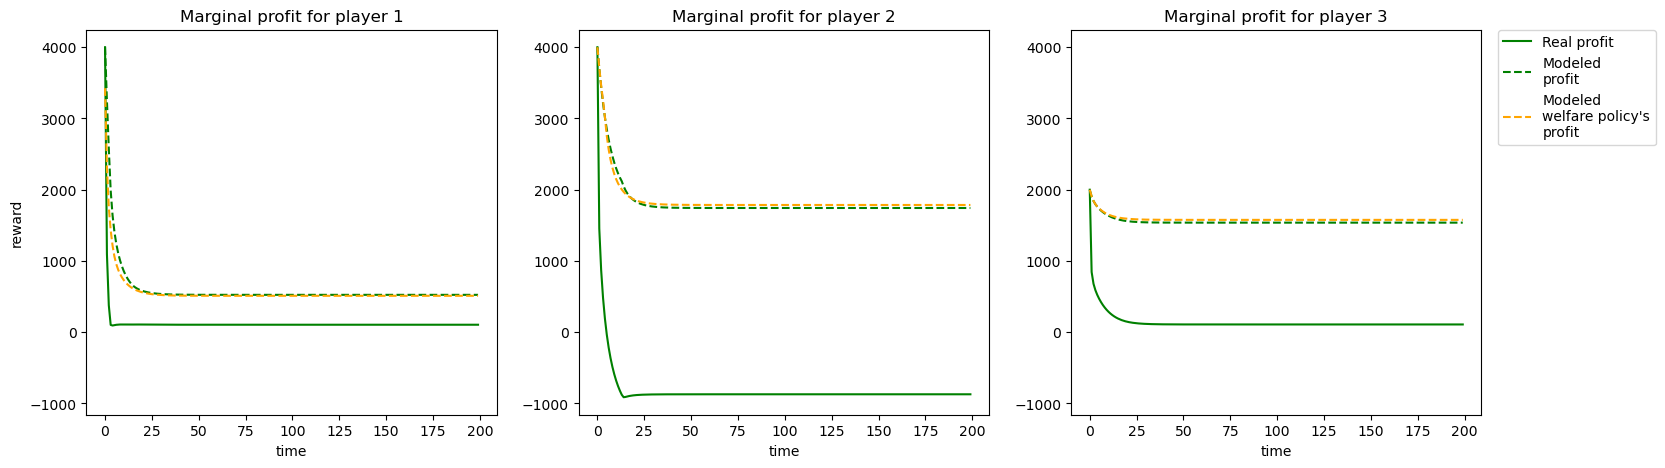

In [18]:
# Display profit evolution
fig_p = plt.figure(figsize=(15+3,5))
ax_p = None
for ii in range(3):
    ax_p = fig_p.add_subplot(1, 3, ii+1, sharey=ax_p)
    ttl = f"Marginal profit for player {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("time")
    if ii == 0:
        ax_p.set_ylabel("reward")
    ax_p.plot(data_si['real_profit'][ii, :], "g-", label="Real profit")
    ax_p.plot(data_si['model_profit'][ii, :], "g--", label="Modeled\nprofit")
    ax_p.plot(data_wf['model_profit'][ii, :], color="orange", linestyle="--", label="Modeled\nwelfare policy's\nprofit")
ax_p.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)